## ML Lab 6 — Image-based ML Master - vision classification workflow

This notebook is for the **first real-world image-based ML lab**: **Distracted Driver Detection**.

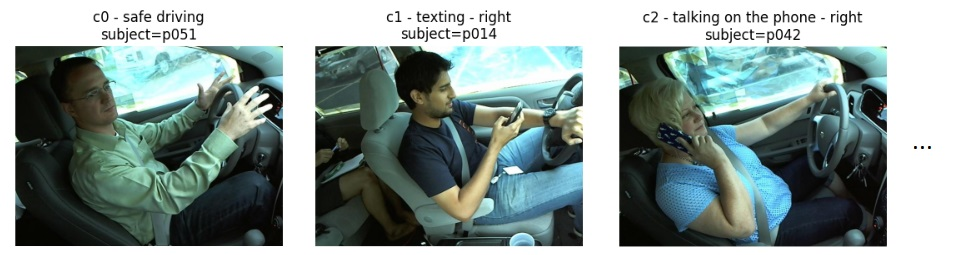

In the previous lab we worked with tables with sklearn models.  
Now the input is not a table row, but an **image**, and we will work with PyTorch CNNs.

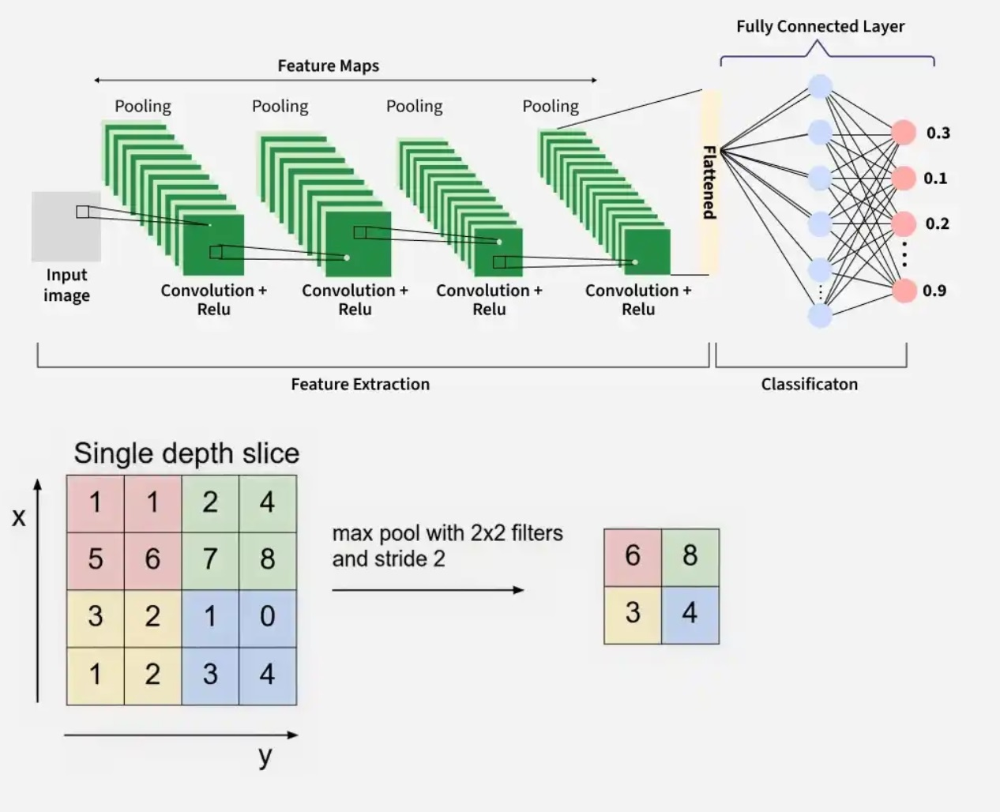

*image based on https://www.geeksforgeeks.org/machine-learning/introduction-convolution-neural-network/*

The goal is to learn:

1. understand what an image dataset looks like in practice
2. inspect image files, labels, classes, and possible problems
3. understand the minimum CNN intuition needed to start
4. build a PyTorch `Dataset` and `DataLoader`
5. split data correctly and avoid **data leakage**
6. train and validate a first CNN classifier


For this lab we use a **real Kaggle competition dataset**:

## State Farm Distracted Driver Detection

The task:

> Given a dashboard camera image of a driver, classify what the driver is doing.

Classes:

- `c0`: safe driving
- `c1`: texting - right
- `c2`: talking on the phone - right
- `c3`: texting - left
- `c4`: talking on the phone - left
- `c5`: operating the radio
- `c6`: drinking
- `c7`: reaching behind
- `c8`: hair and makeup
- `c9`: talking to passenger


## 0. Setup

1. Open this notebook in Kaggle
2. Click **Add Input**
3. Search for **State Farm Distracted Driver Detection** (you will see a red background logo with "StateFarm" text on it)
4. Add the dataset and accept rules
5. Turn on GPU T4 x2:

`Notebook settings -> Accelerator -> GPU`

If GPU is not enabled, the code still runs, but training will be much much much .... slower.

In [1]:
import os
import random
import time
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from IPython.display import display

from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

def seed_everything(seed=42):
    """
    Make results more reproducible.

    In deep learning, perfect reproducibility is not always guaranteed,
    especially on GPU, but this helps a lot.
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

Using device: cuda
GPU name: Tesla T4


## 1. Load Data

For tabular data, each row is usually one instance.

For image data, each instance is usually:

- image path
- label
- maybe extra metadata

Here, we have `driver_imgs_list.csv`.

This file contains:

- `subject`: driver id
- `classname`: class id, like `c0`, `c1`, ...
- `img`: image filename

The `subject` column is very important.  
It will help us discuss **data leakage**.

In [2]:
ROOT = "/kaggle/input/competitions/state-farm-distracted-driver-detection"
TRAIN_DIR = "/kaggle/input/competitions/state-farm-distracted-driver-detection/imgs/train"
csv_path = ROOT +'/'+ "driver_imgs_list.csv"
df = pd.read_csv(csv_path)

In [3]:
df

,subject,classname,img
0,p002,c0,img_44733.jpg
1,p002,c0,img_72999.jpg
2,p002,c0,img_25094.jpg
3,p002,c0,img_69092.jpg
4,p002,c0,img_92629.jpg
...,...,...,...
22419,p081,c9,img_56936.jpg
22420,p081,c9,img_46218.jpg
22421,p081,c9,img_25946.jpg
22422,p081,c9,img_67850.jpg


In [4]:

CLASS_NAMES = {
    "c0": "safe driving",
    "c1": "texting - right",
    "c2": "talking on the phone - right",
    "c3": "texting - left",
    "c4": "talking on the phone - left",
    "c5": "operating the radio",
    "c6": "drinking",
    "c7": "reaching behind",
    "c8": "hair and makeup",
    "c9": "talking to passenger",
}

CLASS_ORDER = [f"c{i}" for i in range(10)]
NUM_CLASSES = len(CLASS_ORDER)

df["class_name"] = df["classname"].map(CLASS_NAMES)


In [5]:
df

,subject,classname,img,class_name
0,p002,c0,img_44733.jpg,safe driving
1,p002,c0,img_72999.jpg,safe driving
2,p002,c0,img_25094.jpg,safe driving
3,p002,c0,img_69092.jpg,safe driving
4,p002,c0,img_92629.jpg,safe driving
...,...,...,...,...
22419,p081,c9,img_56936.jpg,talking to passenger
22420,p081,c9,img_46218.jpg,talking to passenger
22421,p081,c9,img_25946.jpg,talking to passenger
22422,p081,c9,img_67850.jpg,talking to passenger


In [6]:
df["path"] = df.apply(lambda row: str(TRAIN_DIR +'/'+ row["classname"] +'/'+ row["img"]), axis=1)

In [7]:
df

,subject,classname,img,class_name,path
0,p002,c0,img_44733.jpg,safe driving,/kaggle/input/competitions/state-farm-distract...
1,p002,c0,img_72999.jpg,safe driving,/kaggle/input/competitions/state-farm-distract...
2,p002,c0,img_25094.jpg,safe driving,/kaggle/input/competitions/state-farm-distract...
3,p002,c0,img_69092.jpg,safe driving,/kaggle/input/competitions/state-farm-distract...
4,p002,c0,img_92629.jpg,safe driving,/kaggle/input/competitions/state-farm-distract...
...,...,...,...,...,...
22419,p081,c9,img_56936.jpg,talking to passenger,/kaggle/input/competitions/state-farm-distract...
22420,p081,c9,img_46218.jpg,talking to passenger,/kaggle/input/competitions/state-farm-distract...
22421,p081,c9,img_25946.jpg,talking to passenger,/kaggle/input/competitions/state-farm-distract...
22422,p081,c9,img_67850.jpg,talking to passenger,/kaggle/input/competitions/state-farm-distract...


## 2. Exploratory Analysis

Before modeling, we have to explore:

- How many images do we have?
- How many classes?
- Are classes balanced?
- Are there duplicate rows?
- Are there missing files?
- Are images all same size?
- Are there groups/persons/subjects that can cause leakage?


Number of images: 22424
Number of unique drivers: 26
Number of classes: 10

Duplicate rows:
0


,class_id,count,class_name,percent
0,c0,2489,safe driving,11.10
1,c1,2267,texting - right,10.11
2,c2,2317,talking on the phone - right,10.33
3,c3,2346,texting - left,10.46
4,c4,2326,talking on the phone - left,10.37
5,c5,2312,operating the radio,10.31
6,c6,2325,drinking,10.37
7,c7,2002,reaching behind,8.93
8,c8,1911,hair and makeup,8.52
9,c9,2129,talking to passenger,9.49


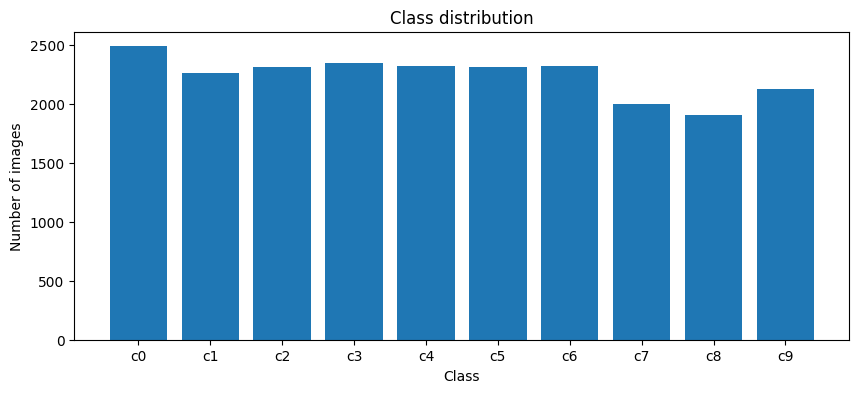

In [8]:
print("Number of images:", len(df))
print("Number of unique drivers:", df["subject"].nunique())
print("Number of classes:", df["classname"].nunique())

print("\nDuplicate rows:")
print(df.duplicated(subset=["subject", "classname", "img"]).sum())

class_counts = (
    df["classname"]
    .value_counts()
    .reindex(CLASS_ORDER)
    .rename_axis("class_id")
    .reset_index(name="count")
)

class_counts["class_name"] = class_counts["class_id"].map(CLASS_NAMES)
class_counts["percent"] = (class_counts["count"] / class_counts["count"].sum() * 100).round(2)

display(class_counts)

plt.figure(figsize=(10, 4))
plt.bar(class_counts["class_id"], class_counts["count"])
plt.xticks(rotation=0)
plt.xlabel("Class")
plt.ylabel("Number of images")
plt.title("Class distribution")
plt.show()

Images per driver:


,count,mean,std,min,25%,50%,75%,max
image_count,26.0,862.461538,214.298713,346.0,752.5,823.0,988.25,1237.0


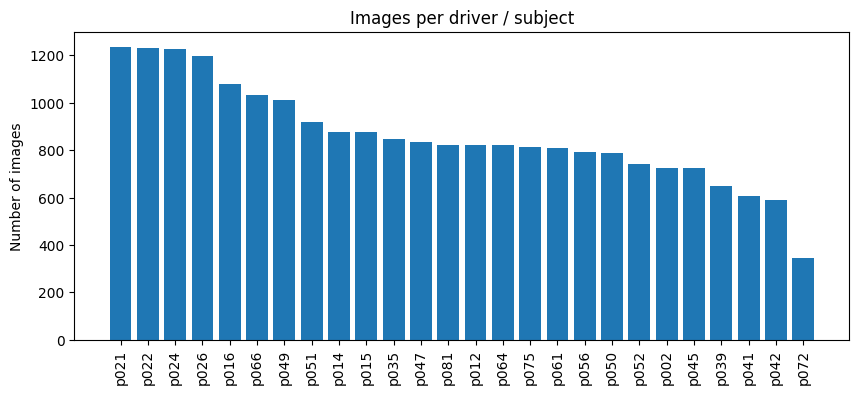


First rows:


,subject,image_count
0,p021,1237
1,p022,1233
2,p024,1226
3,p026,1196
4,p016,1078


In [9]:
# Driver / subject distribution

subject_counts = (
    df["subject"]
    .value_counts()
    .rename_axis("subject")
    .reset_index(name="image_count")
)

print("Images per driver:")
display(subject_counts.describe().T)

plt.figure(figsize=(10, 4))
plt.bar(subject_counts["subject"], subject_counts["image_count"])
plt.xticks(rotation=90)
plt.ylabel("Number of images")
plt.title("Images per driver / subject")
plt.show()

print("\nFirst rows:")
display(subject_counts.head())

In [10]:
# Check image dimensions on a sample.

sample_for_size = df.sample(min(500, len(df)), random_state=42)

sizes = []
for p in sample_for_size["path"]:
    with Image.open(p) as img:
        width, height = img.size
        sizes.append((width, height))

size_df = pd.DataFrame(sizes, columns=["width", "height"])

print("Image size summary from a sample:")
display(size_df.describe().T)

print("\nMost common sizes:")
display(size_df.value_counts().head(10).to_frame("count"))

Image size summary from a sample:


,count,mean,std,min,25%,50%,75%,max
width,500.0,640.0,0.0,640.0,640.0,640.0,640.0,640.0
height,500.0,480.0,0.0,480.0,480.0,480.0,480.0,480.0



Most common sizes:


,,count
width,height,
640,480,500


###  Visual inspection

We should look at real samples because:

- labels may be wrong
- images may be rotated or corrupted
- class differences may be subtle
- background or person identity may leak information
- some augmentations may be dangerous

Example:

For this dataset, **horizontal flipping is dangerous**.

Because classes explicitly contain **left** and **right**.

If we flip an image of `texting - right`, visually it becomes closer to `texting - left`, but the label remains `texting - right`.

So an augmentation that is good in one image problem can be wrong in another.

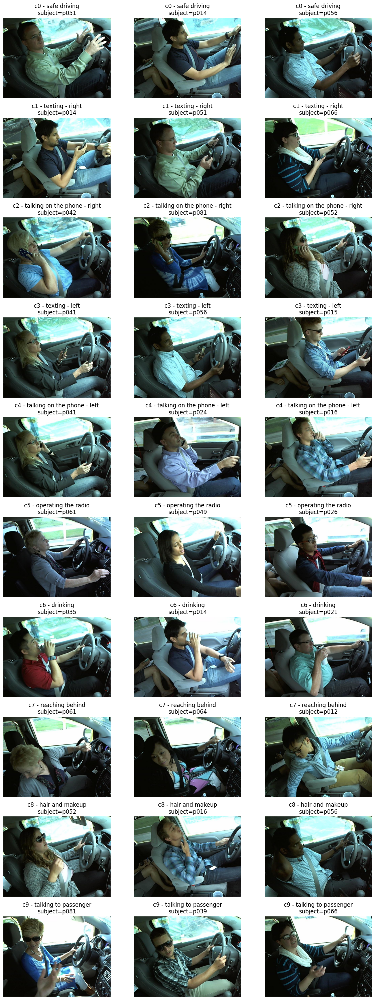

In [11]:
def show_samples_by_class(dataframe, n_per_class=2, seed=42):
    """
    Show a few images from each class.
    """
    rng = np.random.default_rng(seed)

    rows = []
    for class_id in CLASS_ORDER:
        class_df = dataframe[dataframe["classname"] == class_id]
        if len(class_df) == 0:
            continue

        take_n = min(n_per_class, len(class_df))
        sampled_idx = rng.choice(class_df.index, size=take_n, replace=False)
        rows.extend(sampled_idx)

    n_images = len(rows)
    n_cols = n_per_class
    n_rows = int(np.ceil(n_images / n_cols))

    plt.figure(figsize=(4 * n_cols, 3 * n_rows))

    for i, idx in enumerate(rows):
        row = dataframe.loc[idx]
        img = Image.open(row["path"]).convert("RGB")

        ax = plt.subplot(n_rows, n_cols, i + 1)
        ax.imshow(img)
        ax.set_title(f"{row['classname']} - {row['class_name']}\nsubject={row['subject']}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()

show_samples_by_class(df, n_per_class=3)

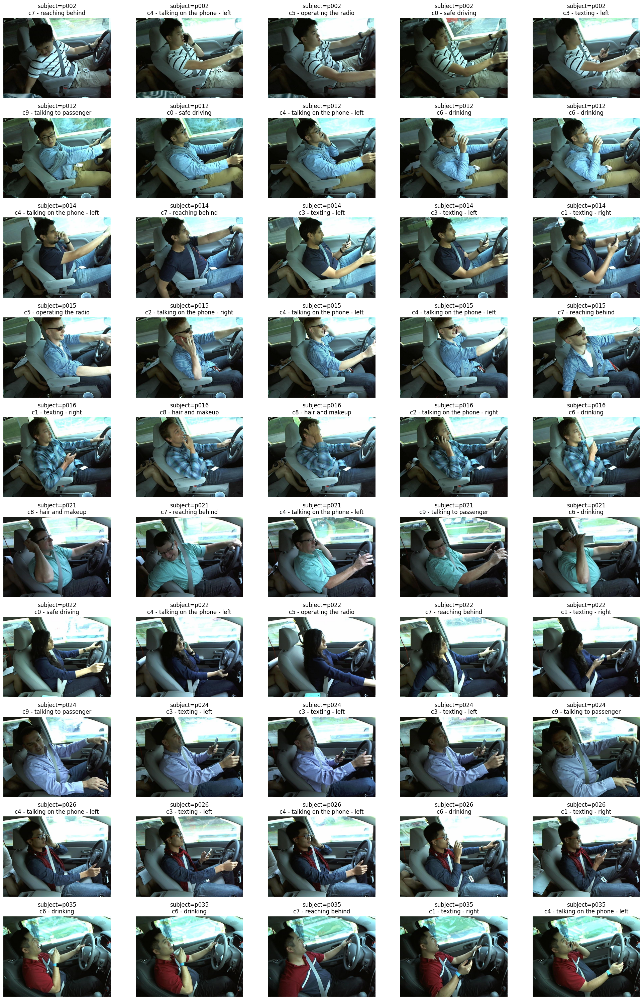

In [12]:
def show_samples_by_subject(dataframe, n_per_subject=3, seed=42, max_subjects=None):
    """
    Show a few images from each subject / driver.
    """
    rng = np.random.default_rng(seed)

    # Make sure class_name exists
    dataframe = dataframe.copy()
    if "class_name" not in dataframe.columns:
        dataframe["class_name"] = dataframe["classname"].map(CLASS_NAMES)

    subjects = sorted(dataframe["subject"].unique())

    if max_subjects is not None:
        subjects = subjects[:max_subjects]

    rows = []

    for subject in subjects:
        subject_df = dataframe[dataframe["subject"] == subject]

        if len(subject_df) == 0:
            continue

        take_n = min(n_per_subject, len(subject_df))
        sampled_idx = rng.choice(subject_df.index, size=take_n, replace=False)
        rows.extend(sampled_idx)

    n_images = len(rows)
    n_cols = n_per_subject
    n_rows = int(np.ceil(n_images / n_cols))

    plt.figure(figsize=(4 * n_cols, 3 * n_rows))

    for i, idx in enumerate(rows):
        row = dataframe.loc[idx]
        img = Image.open(row["path"]).convert("RGB")

        ax = plt.subplot(n_rows, n_cols, i + 1)
        ax.imshow(img)
        ax.set_title(
            f"subject={row['subject']}\n"
            f"{row['classname']} - {row['class_name']}"
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()

show_samples_by_subject(df, n_per_subject=5, max_subjects=10)

## Checking class distribution per subject: leakage risk and validation strategy

Before building a validation split, it is important to understand how the dataset is structured. In this competition, images are not independent random samples: multiple images come from the same driver, called a `subject`. This means that the model can potentially learn driver-specific characteristics such as camera angle, body position, clothing, lighting, car interior, or face/hand appearance.

This creates a possible source of data leakage if images from the same subject appear in both the training and validation sets. In that case, the validation score may look very good, not necessarily because the model learned the true visual differences between distracted-driving classes, but because it recognized patterns associated with a driver already seen during training.

A useful diagnostic is to inspect the distribution of classes within each subject. If each subject has images from all classes in roughly balanced proportions, then the subject identity is less likely to be strongly correlated with a specific class. This reduces the risk that the model can predict the class simply from subject-specific features.

However, this does not completely remove the leakage problem. Even with balanced class distributions, putting the same subject in both training and validation can still make the validation task easier than the real test scenario. The model may still benefit from seeing the same driver during training and validation.

Therefore, the safest validation strategy is a subject-based split: all images from a given subject should belong either to the training set or to the validation set, but not both. This better simulates the real-world goal: generalizing to unseen drivers.

In the following analysis, we inspect how classes are distributed across subjects. The goal is to check whether some subjects are dominated by specific classes and to better understand how important subject-based validation will be for this dataset.

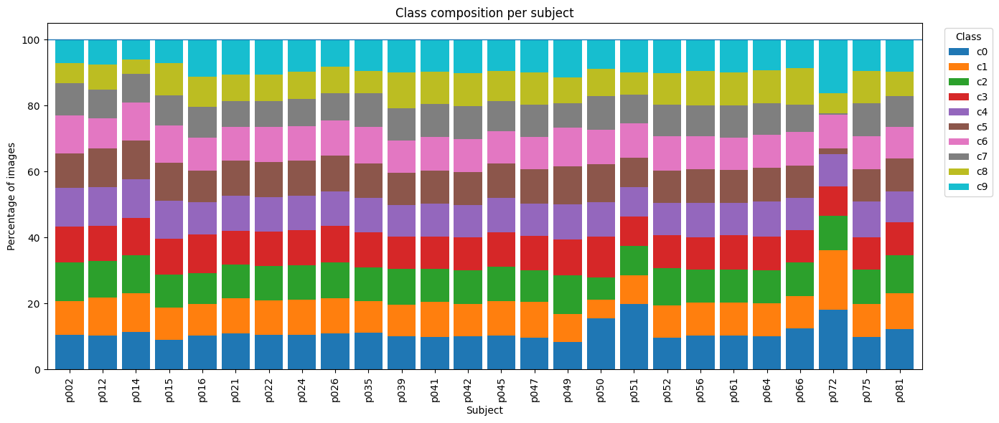

In [13]:
# Class distribution per subject

CLASS_ORDER = [f"c{i}" for i in range(10)]

# Make sure class_name exists
if "class_name" not in df.columns:
    df["class_name"] = df["classname"].map(CLASS_NAMES)

# Count images for each subject-class pair
subject_class_counts = pd.crosstab(
    df["subject"],
    df["classname"]
).reindex(columns=CLASS_ORDER, fill_value=0)

# Convert counts to percentages within each subject
subject_class_percent = (
    subject_class_counts
    .div(subject_class_counts.sum(axis=1), axis=0)
    .mul(100)
    .round(2)
)

subject_class_percent.plot(
    kind="bar",
    stacked=True,
    figsize=(14, 6),
    width=0.85
)

plt.axhline(100, linewidth=1)
plt.xlabel("Subject")
plt.ylabel("Percentage of images")
plt.title("Class composition per subject")
plt.legend(title="Class", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 3. Data Splitting
### The most important practical issue here: data leakage

In a normal random split, images of the **same driver** may appear in both train and validation.

That is dangerous.

The model may learn:

- the driver's face
- clothing
- camera position
- car interior
- lighting

instead of learning the actual behavior.

Then validation accuracy can look very good, but the model may fail on a new driver.

So for this dataset we split by `subject`.

This is called a **group split**.

Same idea in other applications:

- medical data: split by patient
- retail data: split by customer
- time-series: split by time
- video data: split by video/person

In [14]:
# normal random split

random_train_df, random_valid_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["classname"]
)

random_train_subjects = set(random_train_df["subject"])
random_valid_subjects = set(random_valid_df["subject"])
random_overlap = random_train_subjects.intersection(random_valid_subjects)

print("RANDOM SPLIT")
print("Train images:", len(random_train_df))
print("Valid images:", len(random_valid_df))
print("Unique train drivers:", len(random_train_subjects))
print("Unique valid drivers:", len(random_valid_subjects))
print("Drivers appearing in BOTH train and validation:", len(random_overlap))
print("Example overlapping drivers:", sorted(list(random_overlap))[:10])

RANDOM SPLIT
Train images: 17939
Valid images: 4485
Unique train drivers: 26
Unique valid drivers: 26
Drivers appearing in BOTH train and validation: 26
Example overlapping drivers: ['p002', 'p012', 'p014', 'p015', 'p016', 'p021', 'p022', 'p024', 'p026', 'p035']


In [15]:
# group split by driver / subject

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, valid_idx = next(
    gss.split(
        df,
        y=df["classname"],
        groups=df["subject"]
    )
)

train_df = df.iloc[train_idx].reset_index(drop=True)
valid_df = df.iloc[valid_idx].reset_index(drop=True)

train_subjects = set(train_df["subject"])
valid_subjects = set(valid_df["subject"])
overlap = train_subjects.intersection(valid_subjects)

print("GROUP SPLIT BY DRIVER")
print("Train images:", len(train_df))
print("Valid images:", len(valid_df))
print("Unique train drivers:", len(train_subjects))
print("Unique valid drivers:", len(valid_subjects))
print("Drivers appearing in BOTH train and validation:", len(overlap))

print("\nTrain class distribution:")
display(train_df["classname"].value_counts().reindex(CLASS_ORDER).to_frame("train_count"))

print("\nValidation class distribution:")
display(valid_df["classname"].value_counts().reindex(CLASS_ORDER).to_frame("valid_count"))

GROUP SPLIT BY DRIVER
Train images: 17446
Valid images: 4978
Unique train drivers: 20
Unique valid drivers: 6
Drivers appearing in BOTH train and validation: 0

Train class distribution:


,train_count
classname,
c0,1925
c1,1793
c2,1816
c3,1810
c4,1795
c5,1786
c6,1795
c7,1522
c8,1511



Validation class distribution:


,valid_count
classname,
c0,564
c1,474
c2,501
c3,536
c4,531
c5,526
c6,530
c7,480
c8,400


###  We use a smaller subset for testing workflow

Using the full dataset is mandadory for high performance, but when starting to test stuff we need fast feedback.

So we start with a limited number of images per class.

This is a common real workflow:

1. make the pipeline work on a small subset
2. debug everything
3. then scale up

Set these values to `None` if you want to use the full split.

In [16]:
MAX_TRAIN_IMAGES_PER_CLASS = 500
MAX_VALID_IMAGES_PER_CLASS = 150

def sample_per_class(dataframe, max_per_class=None, seed=42):
    """
    Keep at most max_per_class images for each class.
    """
    if max_per_class is None:
        return dataframe.sample(frac=1, random_state=seed).reset_index(drop=True)

    parts = []
    for class_id in CLASS_ORDER:
        class_df = dataframe[dataframe["classname"] == class_id]
        n = min(max_per_class, len(class_df))
        parts.append(class_df.sample(n=n, random_state=seed))

    return pd.concat(parts).sample(frac=1, random_state=seed).reset_index(drop=True)
# random_train_df
train_df_small = sample_per_class(random_train_df, MAX_TRAIN_IMAGES_PER_CLASS)
valid_df_small = sample_per_class(random_valid_df, MAX_VALID_IMAGES_PER_CLASS)

print("Training subset shape:", train_df_small.shape)
print("Validation subset shape:", valid_df_small.shape)

print("\nTraining subset class counts:")
display(train_df_small["classname"].value_counts().reindex(CLASS_ORDER).to_frame("count"))

print("\nValidation subset class counts:")
display(valid_df_small["classname"].value_counts().reindex(CLASS_ORDER).to_frame("count"))

Training subset shape: (5000, 5)
Validation subset shape: (1500, 5)

Training subset class counts:


,count
classname,
c0,500
c1,500
c2,500
c3,500
c4,500
c5,500
c6,500
c7,500
c8,500



Validation subset class counts:


,count
classname,
c0,150
c1,150
c2,150
c3,150
c4,150
c5,150
c6,150
c7,150
c8,150


## 4. Modeling
### Basic CNN 

Until now, we used tabular features like:

`Age`, `Fare`, `Sex`, ...

For an image, the raw input is pixels.

A color image is usually:

`height x width x 3 channels`

The 3 channels are:

- Red
- Green
- Blue

In PyTorch, the image tensor shape is usually:

`channels x height x width`

For a batch:

`batch_size x channels x height x width`

Example:

`64 x 3 x 128 x 128`

means:

- 64 images
- 3 color channels
- 128 height
- 128 width

---

### What does a CNN do?


A CNN does not look at every pixel independently.

It learns small filters that slide over the image.

Early layers learn simple patterns:

- edges
- corners
- color changes

Deeper layers learn more useful combinations:

- hands
- phone-like shapes
- head position
- body posture

The common pattern is:

`Convolution -> ReLU -> Pooling`

Then at the end:

`Flatten / Average Pooling -> Linear layers -> class logits`

### PyTorch Dataset and transforms

In PyTorch, the `Dataset` tells Python:

- where the image file is
- how to open it
- what label it has
- what preprocessing/transforms to apply

The `DataLoader` creates batches.

Important preprocessing for images:

- resize images to same size
- convert image to tensor
- normalize pixel values

For training we may add small augmentation.  
But **no horizontal flip here**, because left/right are part of the labels.

In [17]:
IMG_SIZE = 128

MEAN = [0.5, 0.5, 0.5]
STD = [0.5, 0.5, 0.5]

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    # Small rotation can make model more robust.
    transforms.RandomRotation(degrees=5),

    # Lighting/color changes are realistic.
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10,
        hue=0.02
    ),

    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

valid_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

class_to_idx = {class_id: i for i, class_id in enumerate(CLASS_ORDER)}
idx_to_class = {i: class_id for class_id, i in class_to_idx.items()}

class DriverImageDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        # Open image
        image = Image.open(row["path"]).convert("RGB")

        # Transform image
        if self.transform is not None:
            image = self.transform(image)

        # Convert class id to integer label
        label = class_to_idx[row["classname"]]

        return image, label

train_dataset = DriverImageDataset(train_df_small, transform=train_transform)
valid_dataset = DriverImageDataset(valid_df_small, transform=valid_transform)


print("Train dataset length:", len(train_dataset))
print("Valid dataset length:", len(valid_dataset))

one_image, one_label = train_dataset[0]

print("\nOne image tensor shape:", one_image.shape)
print("One label:", one_label, "->", idx_to_class[one_label], "->", CLASS_NAMES[idx_to_class[one_label]])
print("Pixel min:", one_image.min().item())
print("Pixel mean:", one_image.mean().item())
print("Pixel max:", one_image.max().item())

Train dataset length: 5000
Valid dataset length: 1500

One image tensor shape: torch.Size([3, 128, 128])
One label: 3 -> c3 -> texting - left
Pixel min: -1.0
Pixel mean: -0.3750448226928711
Pixel max: 0.929411768913269


In [18]:
BATCH_SIZE = 64


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    pin_memory=torch.cuda.is_available()
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=torch.cuda.is_available()
)

### Build a first CNN

We build a small CNN from scratch.

The model structure:

1. convolution block
2. convolution block
3. convolution block
4. average pooling
5. linear classifier

The final layer outputs **10 numbers**.

These are called **logits**.

`CrossEntropyLoss` internally converts logits to probabilities using softmax, so we do **not** put softmax inside the model.

In [19]:
class SmallCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        self.features = nn.Sequential(
            # Input: [B, 3, 128, 128]
            nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            # [B, 32, 64, 64]

            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            # [B, 64, 32, 32]

            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            # [B, 128, 16, 16]

            # Convert any remaining spatial size to 4x4
            nn.AdaptiveAvgPool2d((4, 4)),
            # [B, 128, 4, 4]
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=0.30),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(p=0.30),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

model = SmallCNN(num_classes=NUM_CLASSES).to(device)

print(model)

num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTrainable parameters: {num_params:,}")

# Conv2d(64, 128, kernel_size=3)
# Έχει:
# 128 filters * (64 input channels * 3 * 3 + 1 bias) = 73,856 params

SmallCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): AdaptiveAvgPool2d(output_size=(4, 4))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, inplace=False)
    (2): Linear(in_features=2048, out_features=256, bias=True)
    (3): ReLU()
    (4): Dropout(p=0.3, inplace=False)
    (5): Linear(in_features=256, out_features=10, bias=True)
  )
)

Trainable parameters: 620,362


### Train and evaluate functions

In PyTorch we usually write loops.

Training loop:

1. send images and labels to GPU/CPU
2. forward pass
3. compute loss
4. zero gradients
5. backward pass
6. optimizer step

Validation loop:

1. no gradients
2. forward pass
3. compute loss and predictions
4. measure accuracy

This is the same principle as gradient descent from our theory lectures, but now the model is much bigger.

In [20]:
def train_one_epoch(model, dataloader, loss_fn, optimizer, device):
    model.train()

    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    for images, labels in dataloader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Forward
        outputs = model(images)
        loss = loss_fn(outputs, labels)

        # Backward
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Metrics
        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size

        predictions = outputs.argmax(dim=1)
        total_correct += (predictions == labels).sum().item()
        total_examples += batch_size

    avg_loss = total_loss / total_examples
    accuracy = total_correct / total_examples

    return avg_loss, accuracy


def evaluate(model, dataloader, loss_fn, device):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    all_predictions = []
    all_labels = []
    all_probabilities = []

    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            loss = loss_fn(outputs, labels)

            probabilities = torch.softmax(outputs, dim=1)
            predictions = outputs.argmax(dim=1)

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            total_correct += (predictions == labels).sum().item()
            total_examples += batch_size

            all_predictions.append(predictions.cpu())
            all_labels.append(labels.cpu())
            all_probabilities.append(probabilities.cpu())

    avg_loss = total_loss / total_examples
    accuracy = total_correct / total_examples

    all_predictions = torch.cat(all_predictions).numpy()
    all_labels = torch.cat(all_labels).numpy()
    all_probabilities = torch.cat(all_probabilities).numpy()

    return avg_loss, accuracy, all_predictions, all_labels, all_probabilities

### Train the model

We start small.

3 epochs are enough to see the workflow.

For better results, we:

- increase `EPOCHS`
- use more images per class
- use larger image size
- use a better model
- use transfer learning

But first we make sure the workflow is correct.

In [21]:
loss_fn = nn.CrossEntropyLoss()

# If classes were very imbalanced, we could add class weights.

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

EPOCHS = 3

history = []

for epoch in range(EPOCHS):
    start = time.time()

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        loss_fn,
        optimizer,
        device
    )

    valid_loss, valid_acc, valid_pred, valid_true, valid_probs = evaluate(
        model,
        valid_loader,
        loss_fn,
        device
    )

    epoch_time = time.time() - start

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "valid_loss": valid_loss,
        "valid_acc": valid_acc,
        "time_sec": epoch_time,
    })

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"train_loss={train_loss:.4f} | "
        f"train_acc={train_acc:.4f} | "
        f"valid_loss={valid_loss:.4f} | "
        f"valid_acc={valid_acc:.4f} | "
        f"time={epoch_time:.1f}s"
    )

Epoch 1/3 | train_loss=2.2678 | train_acc=0.1316 | valid_loss=1.9989 | valid_acc=0.2980 | time=75.3s
Epoch 2/3 | train_loss=1.7595 | train_acc=0.3654 | valid_loss=1.3659 | valid_acc=0.4873 | time=42.6s
Epoch 3/3 | train_loss=1.3114 | train_acc=0.5110 | valid_loss=1.0472 | valid_acc=0.6107 | time=42.6s


,epoch,train_loss,train_acc,valid_loss,valid_acc,time_sec
0,1,2.267812,0.1316,1.998901,0.298000,75.342885
1,2,1.759497,0.3654,1.365935,0.487333,42.552255
2,3,1.311432,0.5110,1.047161,0.610667,42.578894


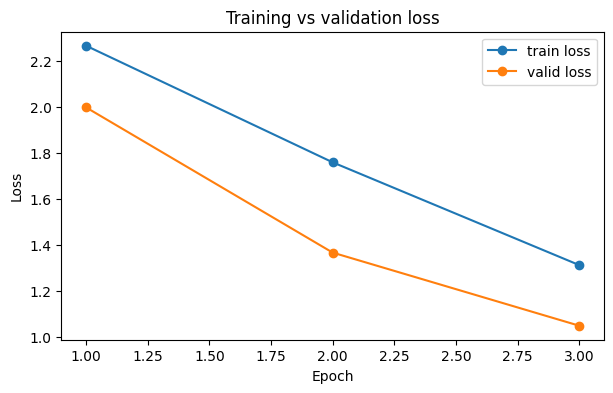

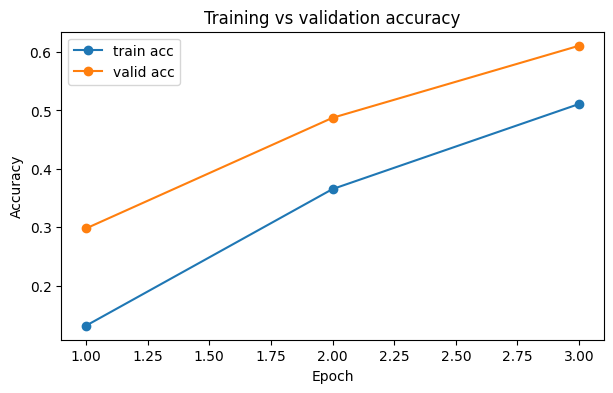

In [22]:
history_df = pd.DataFrame(history)
display(history_df)

plt.figure(figsize=(7, 4))
plt.plot(history_df["epoch"], history_df["train_loss"], marker="o", label="train loss")
plt.plot(history_df["epoch"], history_df["valid_loss"], marker="o", label="valid loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs validation loss")
plt.legend()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history_df["epoch"], history_df["train_acc"], marker="o", label="train acc")
plt.plot(history_df["epoch"], history_df["valid_acc"], marker="o", label="valid acc")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs validation accuracy")
plt.legend()
plt.show()

### Evaluation

In [23]:
# Run final evaluation again, to make sure variables are fresh.
valid_loss, valid_acc, valid_pred, valid_true, valid_probs = evaluate(
    model,
    valid_loader,
    loss_fn,
    device
)

print(f"Validation loss: {valid_loss:.4f}")
print(f"Validation accuracy: {valid_acc:.4f}")

target_names = [f"{class_id}: {CLASS_NAMES[class_id]}" for class_id in CLASS_ORDER]

print("\nClassification report:")
print(classification_report(valid_true, valid_pred, target_names=target_names))

Validation loss: 1.0472
Validation accuracy: 0.6107

Classification report:
                                  precision    recall  f1-score   support

                c0: safe driving       0.50      0.65      0.57       150
             c1: texting - right       0.86      0.79      0.83       150
c2: talking on the phone - right       0.92      0.08      0.15       150
              c3: texting - left       0.57      0.49      0.53       150
 c4: talking on the phone - left       0.54      0.71      0.61       150
         c5: operating the radio       0.89      0.97      0.93       150
                    c6: drinking       0.48      0.71      0.57       150
             c7: reaching behind       0.59      0.96      0.73       150
             c8: hair and makeup       0.51      0.53      0.52       150
        c9: talking to passenger       0.72      0.23      0.35       150

                        accuracy                           0.61      1500
                       macro avg  

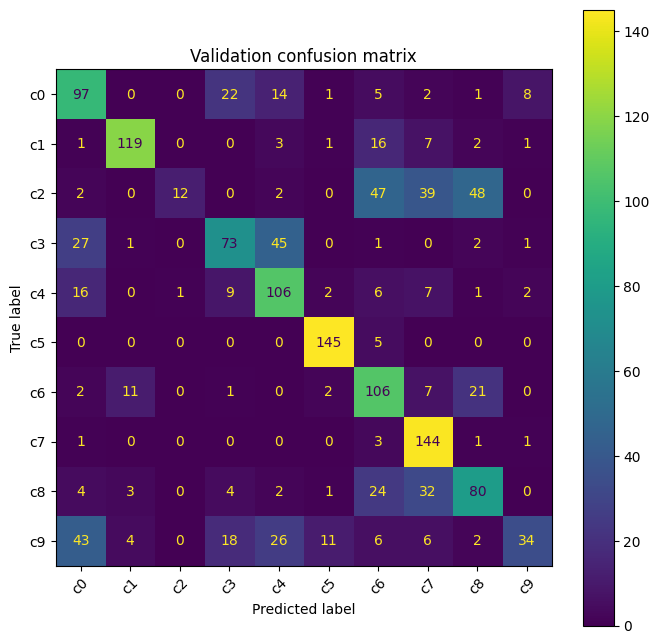

In [24]:
cm = confusion_matrix(valid_true, valid_pred, labels=list(range(NUM_CLASSES)))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_ORDER
)

fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(ax=ax, values_format="d", xticks_rotation=45)
plt.title("Validation confusion matrix")
plt.show()

### What should we try next?

- use full dataset
- larger image size
- better normalization
- crop driver region if needed
- add more augmentations
- train more epochs
- use a stronger CNN
- use transfer learning
- tune learning rate


# Homework 2
## Bonus: +1
### Deadline: 1 week (till 8/5/2026)
---
### With correct homework 1 and 2, it is: 
### +1.5 final grade bonus!

## Mini project

Καλείστε να φτιάξετε compiled notebook το οποίο θα περιέχει self-contained την υλοποίηση και τα σχόλια σας για το παρακάτω task:

---
Φτιάχτε test dataset αποτελούμενο από τρείς διαφορετικούς οδηγούς οι οποίοι εγκυμονούν το μεγαλύτερο leakage σε ένα random-splitted training/validation split. 

Έπειτα, τρέχτε δύο validation splitting strategies:
1. random split
2. group split by driver
με το ίδιο μοντέλο,
για 5 διαφορετικά seeds/runs.

Συγκρίνετε τα averaged validation - testing accuracies για τις 2 validation splitting strategies και καταγράψτε τα συμπεράσματά/σχόλια σας.
Tο ελάχιστο output του notebook πρέπει να είναι ένα απλό print με τα averaged validation - testing accuracies. πχ:

###### print(f"Val accuracy 1: {av_val_acc1:.4f}")
###### print(f"Test accuracy 1: {av_test_acc1:.4f}")

###### print(f"Val accuracy 2: {av_val_acc2:.4f}")
###### print(f"Test accuracy 2: {av_test_acc2:.4f}")
---

Τέλος, καλό είναι το notebook σας να περιέχει μόνο το σχετικό κώδικα/σχόλια που χρειάζεται η άσκηση και γενικά η προσέγγιση σας. Εντελώς περιττά/άσχετα κελιά κώδικα ή κελιά σχολιασμού που δε συνεισφέρουν στην ανάλυση σας, την υλοποίηση σας, και το σχολιασμό σας, θα αφαιρούν απο τη βαθμολογιά. Πχ η 1 μονάδα για σωστή υλοποίηση άσκησης, θα μπορούσε να πέσει έως και - 0.5.


##### Παραδίδεται εντός του deadline, mail με θέμα ML_HW2 - name - am
##### name: το όνομα σας, am: αριθμός μητρώου
##### στο mail: e.pintelas@unipi.gr
##### Στο body του mail απλά μου παρατίθεται το **link (public url)** με το published notebook σας **ή** το **compiled** ipynb notebook/αρχείο σας.

##### Για να κάνετε **publish** το notebook σας, θα πατήσετε πάνω δεξία το "Save Version", το οποίο τρέχει το notebook (προϋποθέτει ότι το .ipynb αρχείο σας είναι απόλυτα μεταγλωτίσημο) και το αποθηκεύει ως μεταγλωτισμένο notebook στο προφίλ σας. Τέλος, πατώντας στο Share button, το κάνετε public για να μπορώ να ανοίξω το link, και μου το στέλνετε.
##### Το **compiled** ipynb αρχείο, το παράγετε τρέχοντας όλο το notebook σας (προϋποθέτει ότι το .ipynb αρχείο σας είναι απόλυτα μεταγλωτίσημο) πατώντας το "Run All" button (πάνω στο κέντρο). Αυτό θα παράξει όλα τα outputs των κελιών του notebook τα οποία αποθηκεύονται στο notebook. Τέλος, πατώντας πάνω αριστερά στο File --> Download Notebook κατεβάσετε το compiled notebook σας το οποίο μου στέλνετε.
